In [5]:
import pandas as pd

df = pd.read_csv("data/pune_weather.csv", skiprows=3)
df.head()

,time,temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm)
0,2016-01-01,31.8,16.6,0.0
1,2016-01-02,31.4,18.8,0.0
2,2016-01-03,30.7,18.6,0.0
3,2016-01-04,30.4,16.1,0.0
4,2016-01-05,30.0,17.9,0.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   time                     3653 non-null   str    
 1   temperature_2m_max (°C)  3653 non-null   float64
 2   temperature_2m_min (°C)  3653 non-null   float64
 3   precipitation_sum (mm)   3653 non-null   float64
dtypes: float64(3), str(1)
memory usage: 114.3 KB


In [7]:
df.isna().sum()

time                       0
temperature_2m_max (°C)    0
temperature_2m_min (°C)    0
precipitation_sum (mm)     0
dtype: int64

In [8]:
df = df.rename(columns={
    "time": "date",
    "temperature_2m_max (°C)": "tmax",
    "temperature_2m_min (°C)": "tmin",
    "precipitation_sum (mm)": "precip",
})
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df.head()

,tmax,tmin,precip
date,,,
2016-01-01,31.8,16.6,0.0
2016-01-02,31.4,18.8,0.0
2016-01-03,30.7,18.6,0.0
2016-01-04,30.4,16.1,0.0
2016-01-05,30.0,17.9,0.0


In [9]:
monthly = df.resample("MS").agg({"tmax": "mean", "tmin": "mean", "precip": "sum"})
monthly.head(12)

,tmax,tmin,precip
date,,,
2016-01-01,29.996774,16.690323,0.1
2016-02-01,33.113793,18.586207,4.0
2016-03-01,35.587097,20.822581,10.8
2016-04-01,38.476667,22.293333,11.2
2016-05-01,36.567742,23.396774,21.7
2016-06-01,30.153333,23.336667,205.1
2016-07-01,25.580645,22.216129,295.6
2016-08-01,25.725806,21.800000,288.3
2016-09-01,26.283333,21.256667,424.2


In [10]:
yearly = df.resample("YS").agg({"tmax": "mean", "tmin": "mean", "precip": "sum"})
yearly

,tmax,tmin,precip
date,,,
2016-01-01,30.678142,20.395902,1329.2
2017-01-01,30.529589,19.673425,935.4
2018-01-01,30.574521,19.841370,680.9
2019-01-01,30.486575,19.853973,1480.4
2020-01-01,30.182787,19.956831,1485.2
2021-01-01,29.877260,19.986301,952.8
2022-01-01,30.543288,19.548767,1076.7
2023-01-01,31.035342,19.892055,782.0
2024-01-01,31.275137,20.326503,1413.1


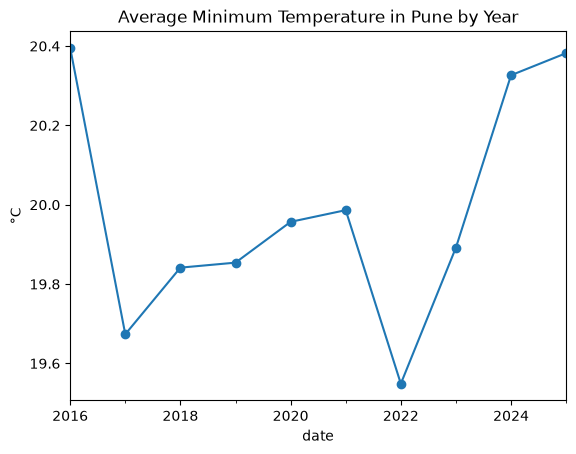

In [16]:
import matplotlib.pyplot as plt

ax = yearly["tmin"].plot(marker="o", title="Average Minimum Temperature in Pune by Year")
ax.set_ylabel("°C")
plt.savefig("images/yearly_min_temp.png", bbox_inches="tight")
plt.show()

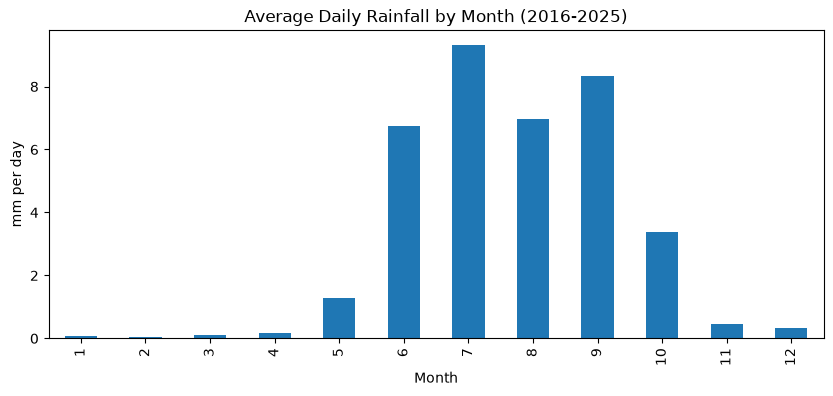

In [17]:
ax = df.groupby(df.index.month)["precip"].mean().plot(kind="bar", figsize=(10, 4), title="Average Daily Rainfall by Month (2016-2025)")
ax.set_xlabel("Month")
ax.set_ylabel("mm per day")
plt.savefig("images/monthly_rainfall.png", bbox_inches="tight")
plt.show()